# **Proyek Pengolahan Sinyal Digital Kelompok 7**

## Analisis Jenis Sinyal Bunyi Lingkungan Menggunakan Visualisasi Spektrogram dan Ekstraksi Fitur MFCC

### Nama Anggota:
1. Yanaka Sofia Pardede (24031554065)
2. Fajria Rasmi Ridha Rumkel (24031554191)
3. Shakyla Andhara Chandraningtyas (24031554199)

## **Install yt-dlp di Colab**

In [1]:
!pip install yt-dlp librosa soundfile matplotlib numpy

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 180.3/180.3 kB 2.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.3/3.3 MB 26.1 MB/s eta 0:00:00


### **Mendownload Audio Tiktok ke Colab**


In [2]:
import yt_dlp

def download_tiktok_audio(url, output_name):
    ydl_opts = {
        "format": "bestaudio/best",
        "outtmpl": output_name + ".%(ext)s",
        "postprocessors": [
            {"key": "FFmpegExtractAudio", "preferredcodec": "mp3", "preferredquality": "192"}
        ]
    }

    with yt_dlp.YoutubeDL(ydl_opts) as ydl:
        ydl.download([url])

    print(f"Audio downloaded: {output_name}.mp3")

### **Mendownload Audio 5 Jenis Suara dari Tiktok**

In [3]:
download_tiktok_audio("https://vt.tiktok.com/ZSf5xsWG5/", "burung")
download_tiktok_audio("https://vt.tiktok.com/ZSf5Q1Wfo/", "hujan")
download_tiktok_audio("https://vt.tiktok.com/ZSf5xqCay/", "kendaraan")
download_tiktok_audio("https://vt.tiktok.com/ZSfmbjQSx/", "mesin")
download_tiktok_audio("https://vt.tiktok.com/ZSfmbe33E/", "angin")

[vm.tiktok] Extracting URL: https://vt.tiktok.com/ZSf5xsWG5/
[vm.tiktok] ZSf5xsWG5: Downloading webpage
[TikTok] Extracting URL: https://www.tiktok.com/@arcadia_bf/video/7237055570161765638?_r=1&_t=ZS-91iZTfGZ6gx
[TikTok] 7237055570161765638: Downloading webpage
[info] 7237055570161765638: Downloading 1 format(s): bytevc1_720p_148675-1
[download] Destination: burung.mp4
[download] 100% of 1014.92KiB in 00:00:00 at 2.11MiB/s   
[ExtractAudio] Destination: burung.mp3
Deleting original file burung.mp4 (pass -k to keep)
Audio downloaded: burung.mp3
[vm.tiktok] Extracting URL: https://vt.tiktok.com/ZSf5Q1Wfo/
[vm.tiktok] ZSf5Q1Wfo: Downloading webpage
[TikTok] Extracting URL: https://www.tiktok.com/@sleep.soft1/video/7536441020343422221?_r=1&_t=ZS-91iZZP4jLa4
[TikTok] 7536441020343422221: Downloading webpage
[info] 7536441020343422221: Downloading 1 format(s): bytevc1_720p_1051098-1
[download] Destination: hujan.mp4
[download] 100% of   15.55MiB in 00:00:00 at 39.71MiB/s  
[ExtractAudio] De

## **Memutar 5 Jenis Suara, Set Sample Rate & Durasi**

### **Memutar Audio Burung**

In [4]:
from IPython.display import Audio
Audio("burung.mp3")

### **Memutar Audio Hujan**

In [5]:
from IPython.display import Audio
Audio("hujan.mp3")

### **Memutar Audio Kendaraan**

In [6]:
from IPython.display import Audio
Audio("kendaraan.mp3")

### **Memutar Audio Mesin**

In [7]:
from IPython.display import Audio
Audio("mesin.mp3")

### **Memutar Audio Angin**

In [8]:
from IPython.display import Audio
Audio("angin.mp3")

## **Import Library**

In [9]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
import numpy as np
import os

### **Analisis Suara & Load Audio**

In [10]:
def load_audio(nama_file, durasi_fix=60):
    if not os.path.exists(nama_file):
        print(f"File '{nama_file}' tidak ditemukan!")
        return None, None, None

    y, sr = librosa.load(nama_file, sr=None, duration=durasi_fix)
    durasi = librosa.get_duration(y=y, sr=sr)
    batas = min(durasi_fix, durasi)

    return y, sr, batas

### **Frequency Domain (FFT)**

In [11]:
def compute_fft(y, sr):
    n = len(y)
    Y = np.fft.fft(y)
    freqs = np.fft.fftfreq(n, 1/sr)

    half = n // 2
    freqs_pos = freqs[:half]
    magnitude = np.abs(Y[:half])

    return freqs_pos, magnitude

### **Spectogram**

In [12]:
def compute_spectrogram(y):
    D = librosa.stft(y)
    S_db = librosa.amplitude_to_db(np.abs(D), ref=np.max)
    return S_db

### **MFCC**

In [13]:
def compute_mfcc(y, sr):
    mfccs = librosa.feature.mfcc(y=y, sr=sr, n_mfcc=13)
    return mfccs

## **Membuat Grafik**

In [14]:
def analyze_audio_frequency(nama_file, label, durasi_fix=60):

    y, sr, batas = load_audio(nama_file, durasi_fix)
    if y is None:
        return

    freqs, magnitude = compute_fft(y, sr)
    S_db = compute_spectrogram(y)
    mfccs = compute_mfcc(y, sr)

    fig, ax = plt.subplots(nrows=4, figsize=(15, 18), constrained_layout=True)

    librosa.display.waveshow(y, sr=sr, ax=ax[0], color='grey')
    ax[0].set_title(f'1. Time Domain (Waveform) - {label}', fontweight='bold')
    ax[0].set_ylabel('Amplitudo', fontweight='bold')
    ax[0].set_xlabel('Waktu (detik)', fontweight='bold')
    ax[0].grid(True, linestyle='--', alpha=0.5)
    ax[0].set_xlim(0, batas)
    ax[0].set_xticks(np.arange(0, batas+1, 5))

    for tick in ax[0].get_xticklabels():
        tick.set_fontweight('bold')
    for tick in ax[0].get_yticklabels():
        tick.set_fontweight('bold')

    ax[1].plot(freqs, magnitude, color='pink')
    ax[1].set_title(f'2. Frequency Domain (FFT Spectrum) - {label}', fontweight='bold')
    ax[1].set_ylabel('Magnitude', fontweight='bold')
    ax[1].set_xlabel('Frekuensi (Hz)', fontweight='bold')
    ax[1].grid(True, linestyle='--', alpha=0.5)
    ax[1].set_xlim(0, 8000)

    for tick in ax[1].get_xticklabels():
        tick.set_fontweight('bold')
    for tick in ax[1].get_yticklabels():
        tick.set_fontweight('bold')

    img1 = librosa.display.specshow(S_db, sr=sr, x_axis='time', y_axis='log', ax=ax[2])
    ax[2].set_title(f'3. Spektrogram - {label}', fontweight='bold')
    ax[2].set_ylabel('Frekuensi (Hz)', fontweight='bold')
    ax[2].set_xlabel('Waktu (detik)', fontweight='bold')
    fig.colorbar(img1, ax=ax[2])
    ax[2].set_xlim(0, batas)
    ax[2].set_xticks(np.arange(0, batas+1, 5))

    for tick in ax[2].get_xticklabels():
        tick.set_fontweight('bold')
    for tick in ax[2].get_yticklabels():
        tick.set_fontweight('bold')

    img2 = librosa.display.specshow(mfccs, sr=sr, x_axis='time', ax=ax[3])
    ax[3].set_title(f'4. MFCC - {label}', fontweight='bold')
    ax[3].set_ylabel('Koefisien MFCC', fontweight='bold')
    ax[3].set_xlabel('Waktu (detik)', fontweight='bold')
    fig.colorbar(img2, ax=ax[3])
    ax[3].set_xlim(0, batas)
    ax[3].set_xticks(np.arange(0, batas+1, 5))

    for tick in ax[3].get_xticklabels():
        tick.set_fontweight('bold')
    for tick in ax[3].get_yticklabels():
        tick.set_fontweight('bold')

    nama_gambar = nama_file.replace(".mp3", f"_{label.replace(' ', '_')}.png")
    plt.savefig(nama_gambar, dpi=300)
    print(f"Grafik disimpan sebagai: {nama_gambar}")
    plt.show()

### **Analisis Suara Burung**

Grafik disimpan sebagai: burung_Suara_Burung.png


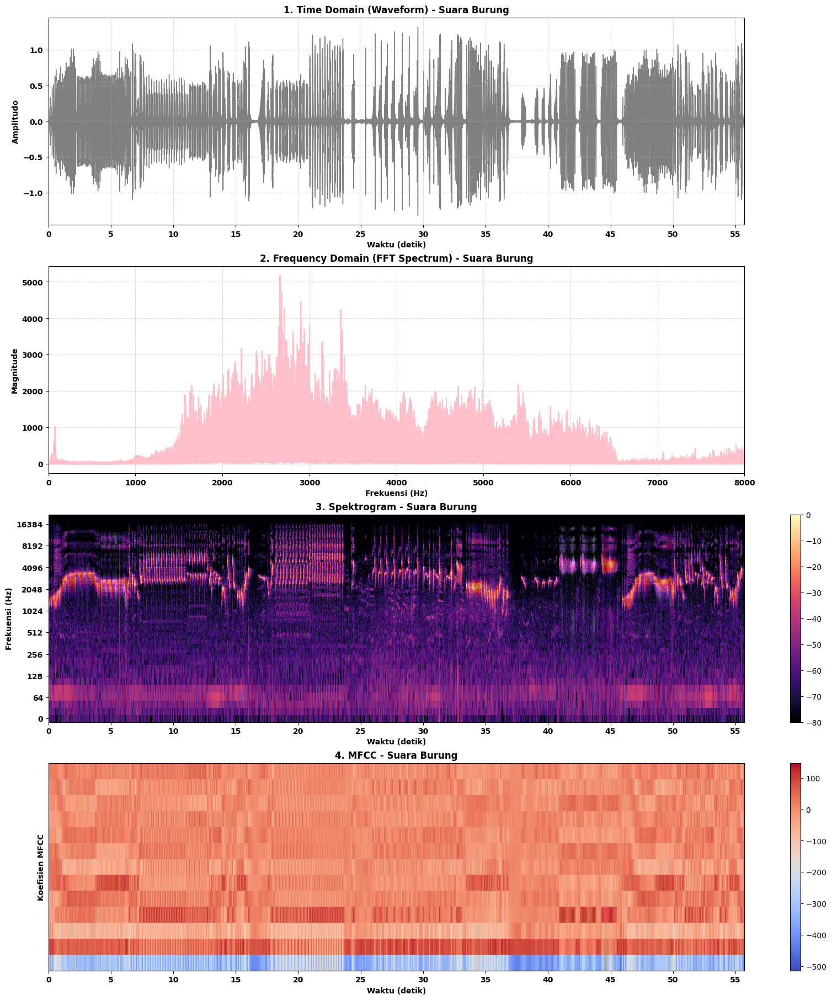

In [15]:
analyze_audio_frequency("burung.mp3", "Suara Burung", durasi_fix=60)

### **Analisis Suara Hujan**

Grafik disimpan sebagai: hujan_Suara_Hujan.png


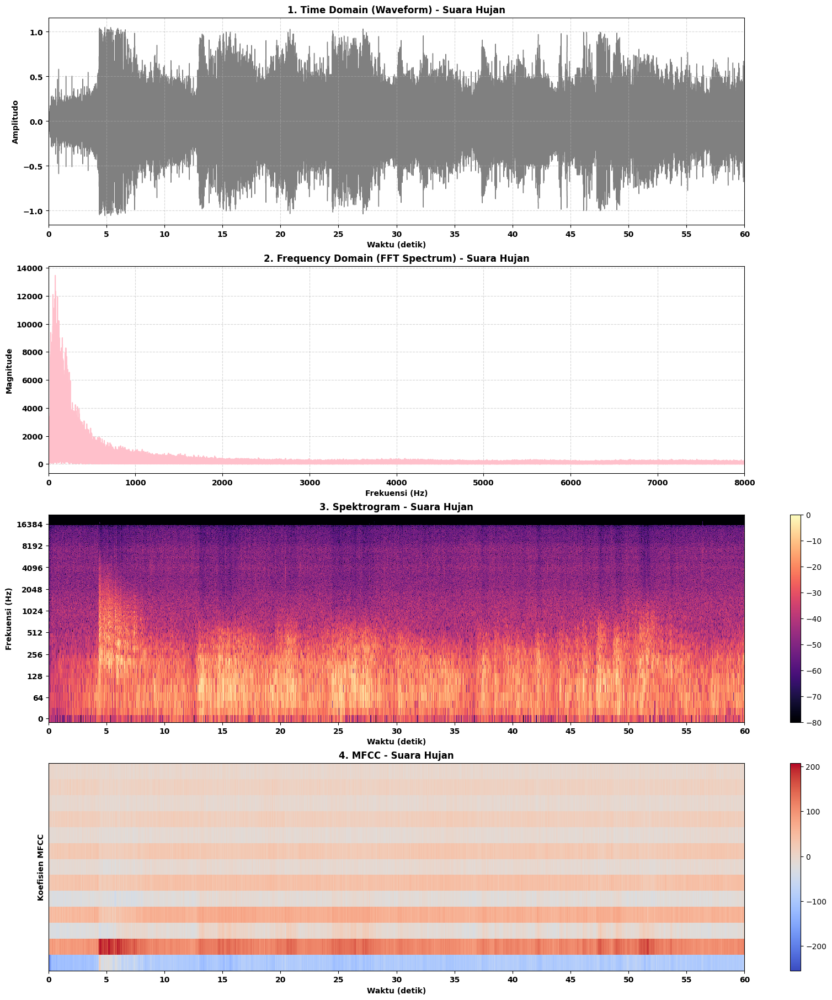

In [16]:
analyze_audio_frequency("hujan.mp3", "Suara Hujan", durasi_fix=60)

### **Analisis Suara Kendaraan**

Grafik disimpan sebagai: kendaraan_Suara_Kendaraan.png


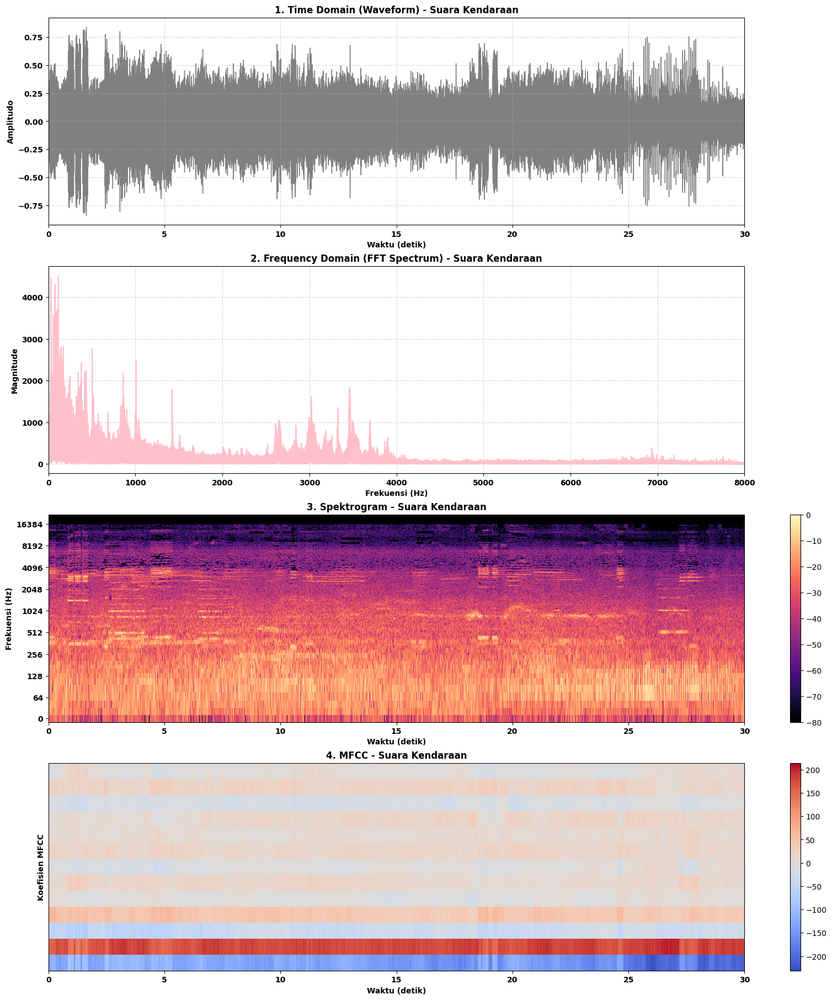

In [17]:
analyze_audio_frequency("kendaraan.mp3", "Suara Kendaraan", durasi_fix=30)

### **Analisis Suara Mesin**

Grafik disimpan sebagai: mesin_Suara_Mesin.png


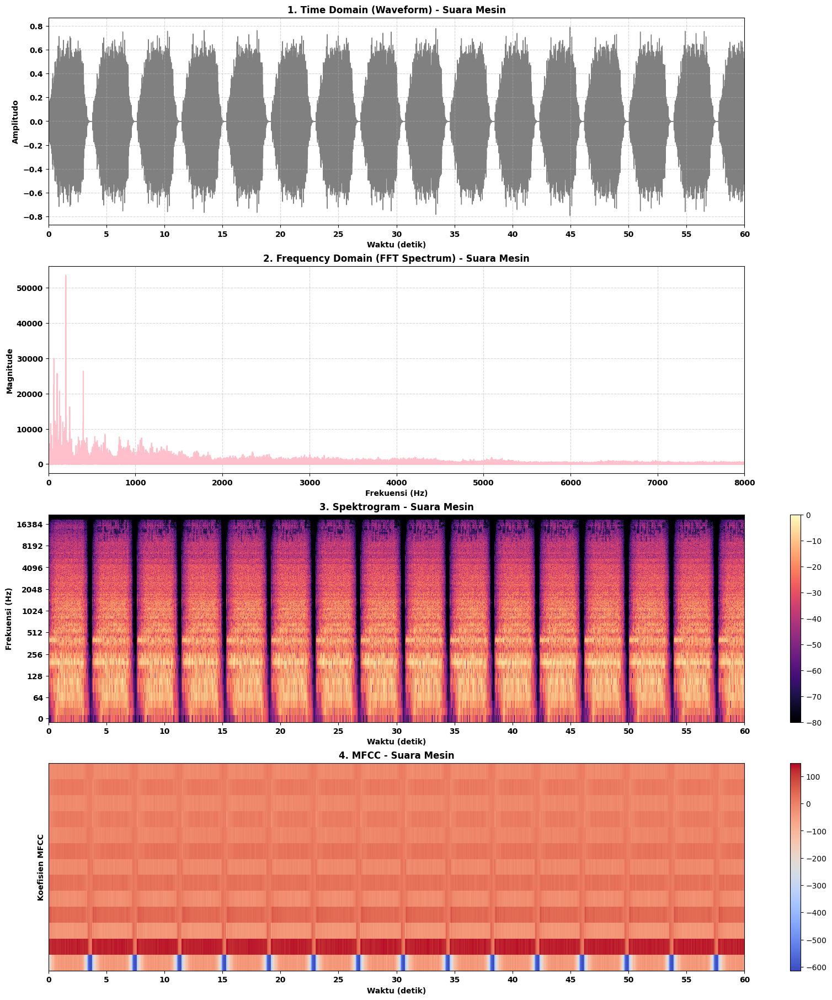

In [18]:
analyze_audio_frequency("mesin.mp3", "Suara Mesin", durasi_fix=60)

### **Analisis Suara Angin**

Grafik disimpan sebagai: angin_Suara_Angin.png


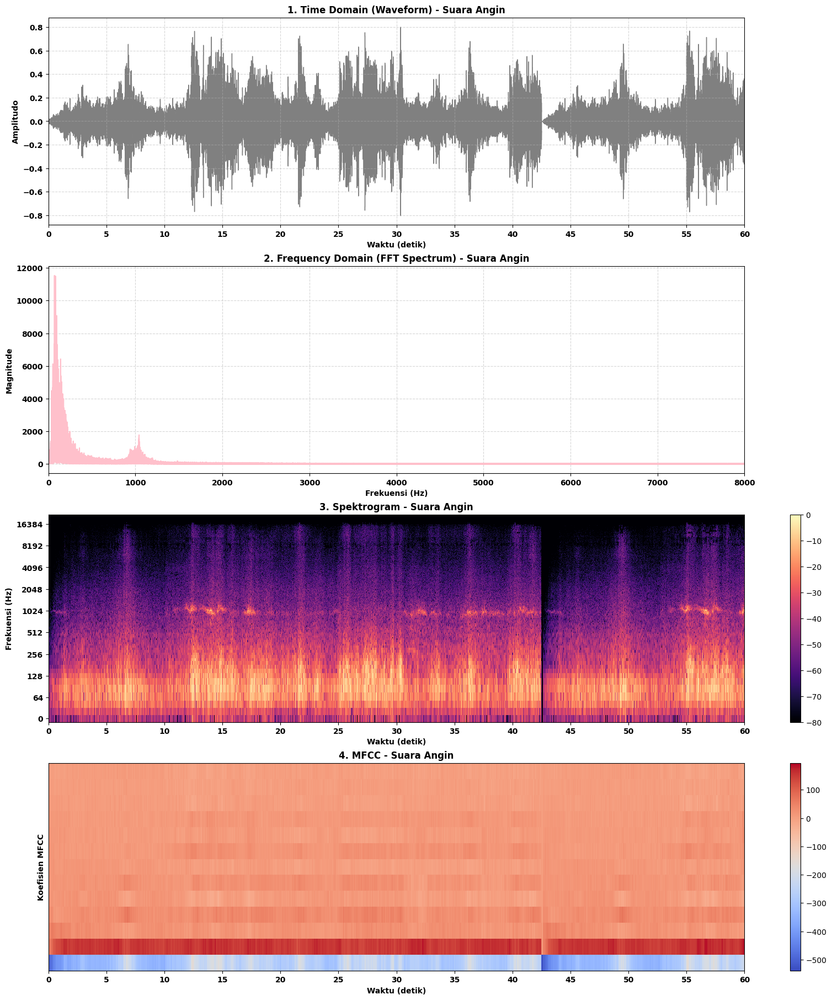

In [19]:
analyze_audio_frequency("angin.mp3", "Suara Angin", durasi_fix=60)

## **Rata-Rata Metode**

### **Menghitung rata-rata Waveform**

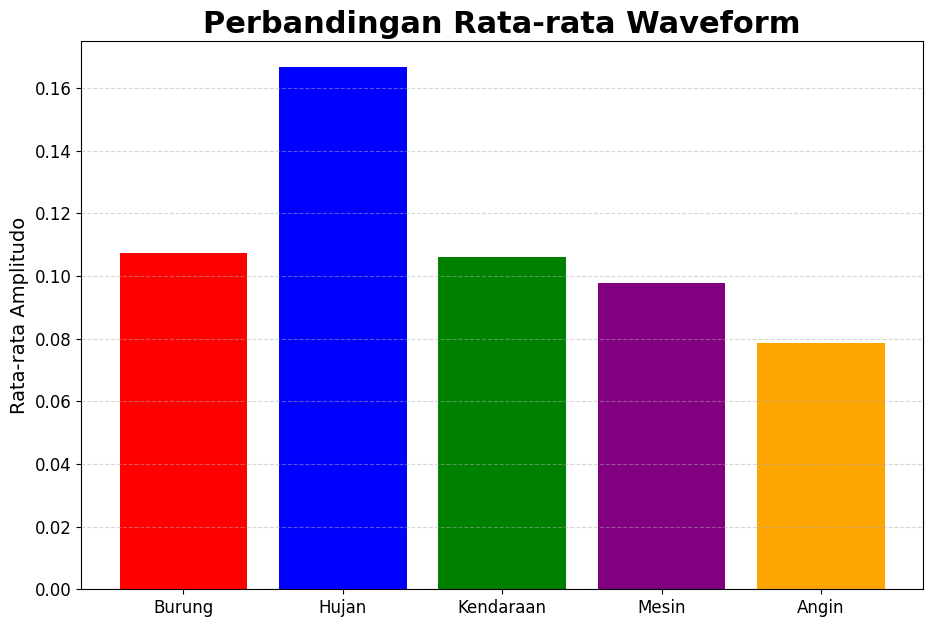

In [46]:
import matplotlib.pyplot as plt
import numpy as np

labels = ["Burung", "Hujan", "Kendaraan", "Mesin", "Angin"]

y_burung, sr_burung, _ = load_audio("burung.mp3", durasi_fix=60)
y_hujan, sr_hujan, _ = load_audio("hujan.mp3", durasi_fix=60)
y_kendaraan, sr_kendaraan, _ = load_audio("kendaraan.mp3", durasi_fix=30)
y_mesin, sr_mesin, _ = load_audio("mesin.mp3", durasi_fix=60)
y_angin, sr_angin, _ = load_audio("angin.mp3", durasi_fix=60)

colors = ["red", "blue", "green", "purple", "orange"]

wave_means = [
    np.mean(np.abs(y_burung)),
    np.mean(np.abs(y_hujan)),
    np.mean(np.abs(y_kendaraan)),
    np.mean(np.abs(y_mesin)),
    np.mean(np.abs(y_angin)),
]

plt.figure(figsize=(18, 12))

plt.subplot(2, 2, 1)
plt.bar(labels, wave_means, color=colors)

plt.title(
    "Perbandingan Rata-rata Waveform",
    fontsize=22, fontweight="bold", loc="center"
)

plt.ylabel("Rata-rata Amplitudo", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(axis="y", linestyle="--", alpha=0.5)

plt.tight_layout()
plt.show()

In [47]:
import pandas as pd

data_waveform = {
    "Burung": np.mean(np.abs(y_burung)),
    "Hujan": np.mean(np.abs(y_hujan)),
    "Kendaraan": np.mean(np.abs(y_kendaraan)),
    "Mesin": np.mean(np.abs(y_mesin)),
    "Angin": np.mean(np.abs(y_angin))
}

df_waveform = pd.DataFrame([data_waveform]).round(6)
print("RATA-RATA AMPLITUDO WAVEFORM")
print(df_waveform)

RATA-RATA AMPLITUDO WAVEFORM
   Burung     Hujan  Kendaraan     Mesin     Angin
0  0.1072  0.166519   0.106033  0.097731  0.078512


### **Menghitung rata-rata FFT**

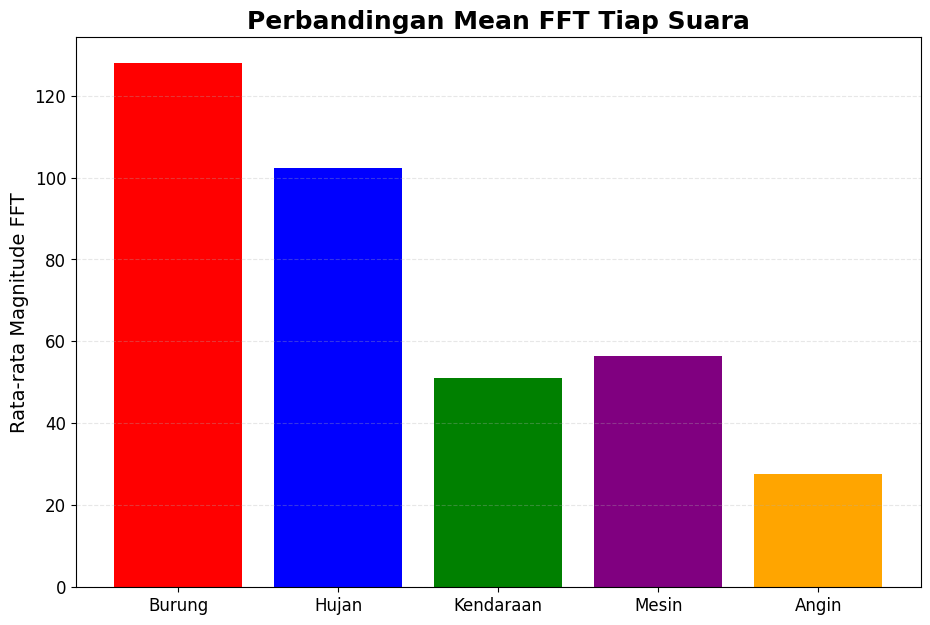

In [48]:
_, fft_m_burung = compute_fft(y_burung, sr_burung)
_, fft_m_hujan = compute_fft(y_hujan, sr_hujan)
_, fft_m_kendaraan = compute_fft(y_kendaraan, sr_kendaraan)
_, fft_m_mesin = compute_fft(y_mesin, sr_mesin)
_, fft_m_angin = compute_fft(y_angin, sr_angin)

colors_fft = ["red", "blue", "green", "purple", "orange"]

fft_means = [
    np.mean(np.abs(fft_m_burung)),
    np.mean(np.abs(fft_m_hujan)),
    np.mean(np.abs(fft_m_kendaraan)),
    np.mean(np.abs(fft_m_mesin)),
    np.mean(np.abs(fft_m_angin)),
]

plt.figure(figsize=(18, 12))

plt.subplot(2, 2, 2)
plt.bar(labels, fft_means, color=colors_fft)

plt.title(
    "Perbandingan Mean FFT Tiap Suara",
    fontsize=18,
    fontweight="bold",
    loc="center"
)

plt.ylabel("Rata-rata Magnitude FFT", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [49]:
data_fft = {
    "Burung": np.mean(np.abs(fft_m_burung)),
    "Hujan": np.mean(np.abs(fft_m_hujan)),
    "Kendaraan": np.mean(np.abs(fft_m_kendaraan)),
    "Mesin": np.mean(np.abs(fft_m_mesin)),
    "Angin": np.mean(np.abs(fft_m_angin))
}

df_fft = pd.DataFrame([data_fft]).round(6)
print("MEAN ABS FFT")
print(df_fft)

MEAN ABS FFT
       Burung       Hujan  Kendaraan      Mesin      Angin
0  127.837013  102.320541  51.185749  56.365368  27.709406


### **Menghitung rata-rata Spectogram**

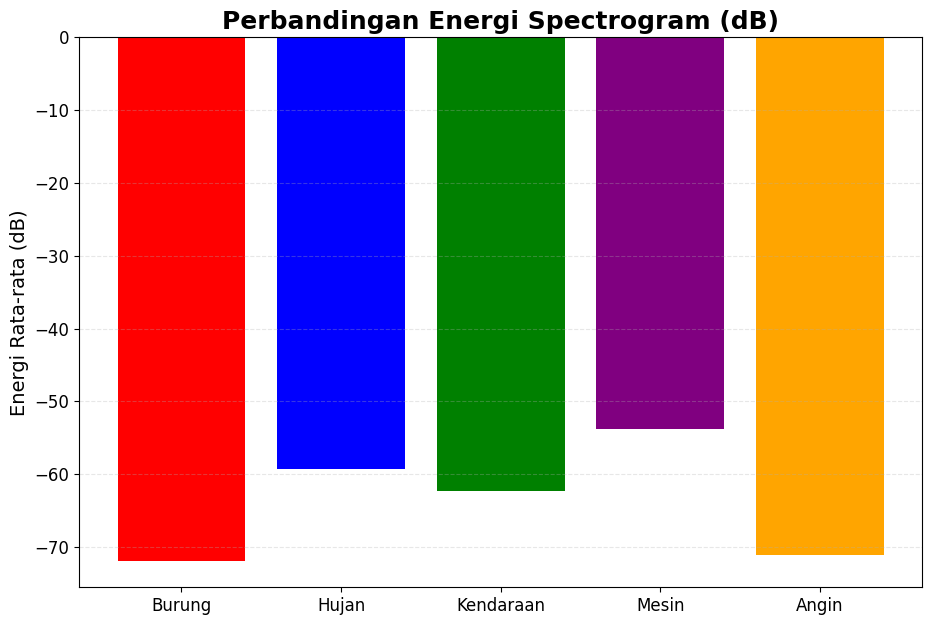

In [50]:
spec_burung = compute_spectrogram(y_burung)
spec_hujan = compute_spectrogram(y_hujan)
spec_kendaraan = compute_spectrogram(y_kendaraan)
spec_mesin = compute_spectrogram(y_mesin)
spec_angin = compute_spectrogram(y_angin)

colors_spec = ["red", "blue", "green", "purple", "orange"]

spec_means = [
    np.mean(spec_burung),
    np.mean(spec_hujan),
    np.mean(spec_kendaraan),
    np.mean(spec_mesin),
    np.mean(spec_angin),
]

plt.figure(figsize=(18, 12))

plt.subplot(2, 2, 3)
plt.bar(labels, spec_means, color=colors_spec)

plt.title(
    "Perbandingan Energi Spectrogram (dB)",
    fontsize=18,
    fontweight="bold",
    loc="center"
)

plt.ylabel("Energi Rata-rata (dB)", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [53]:
data_spectrogram = {
    "Burung"    : np.mean(spec_burung),
    "Hujan"     : np.mean(spec_hujan),
    "Kendaraan" : np.mean(spec_kendaraan),
    "Mesin"     : np.mean(spec_mesin),
    "Angin"     : np.mean(spec_angin)
}

df_spectrogram = pd.DataFrame([data_spectrogram]).round(6)
print("RATA-RATA SPEKTROGRAM (dB)")
print(df_spectrogram)

RATA-RATA SPEKTROGRAM (dB)
      Burung      Hujan  Kendaraan      Mesin      Angin
0 -71.919777 -59.240395 -62.243015 -53.747417 -71.112633


### **Menghitung rata-rata MFCC**

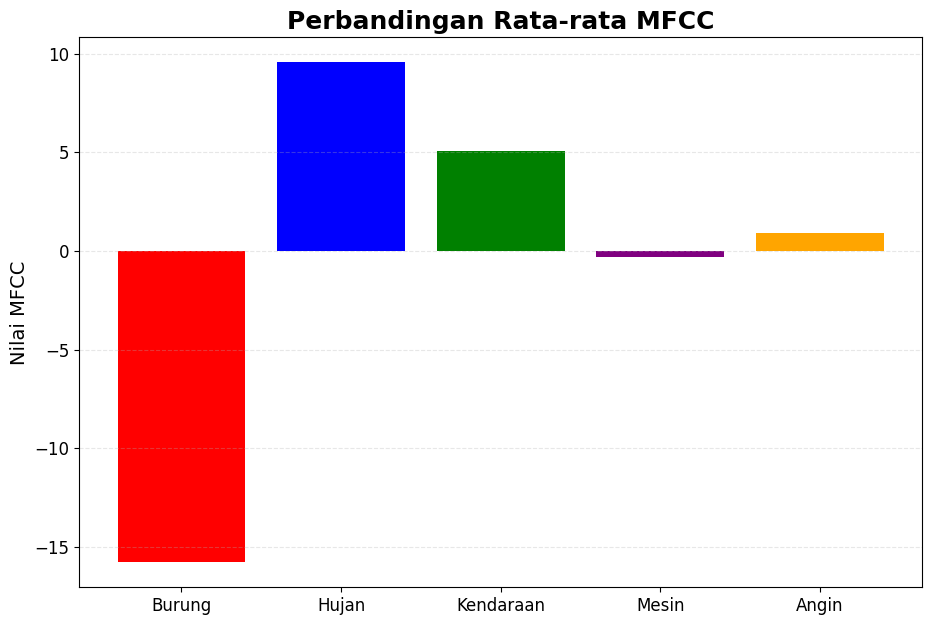

In [52]:
mfcc_burung = compute_mfcc(y_burung, sr_burung)
mfcc_hujan = compute_mfcc(y_hujan, sr_hujan)
mfcc_kendaraan = compute_mfcc(y_kendaraan, sr_kendaraan)
mfcc_mesin = compute_mfcc(y_mesin, sr_mesin)
mfcc_angin = compute_mfcc(y_angin, sr_angin)

colors_mfcc = ["red", "blue", "green", "purple", "orange"]

mfcc_means = [
    np.mean(mfcc_burung),
    np.mean(mfcc_hujan),
    np.mean(mfcc_kendaraan),
    np.mean(mfcc_mesin),
    np.mean(mfcc_angin),
]

plt.figure(figsize=(18, 12))

plt.subplot(2, 2, 4)
plt.bar(labels, mfcc_means, color=colors_mfcc)

plt.title(
    "Perbandingan Rata-rata MFCC",
    fontsize=18,
    fontweight="bold",
    loc="center"
)

plt.ylabel("Nilai MFCC", fontsize=14)
plt.xticks(fontsize=12)
plt.yticks(fontsize=12)

plt.grid(axis='y', linestyle='--', alpha=0.3)

plt.tight_layout()
plt.show()

In [54]:
data = {
    "Burung"    : [np.mean(mfcc_burung)],
    "Hujan"     : [np.mean(mfcc_hujan)],
    "Kendaraan" : [np.mean(mfcc_kendaraan)],
    "Mesin"     : [np.mean(mfcc_mesin)],
    "Angin"     : [np.mean(mfcc_angin)]
}

df = pd.DataFrame(data)
print("RATA-RATA MFCC")
print(df)

RATA-RATA MFCC
      Burung     Hujan  Kendaraan     Mesin     Angin
0 -15.787292  9.567204   5.085218 -0.290339  0.918318


## **Menggabungkan 5 Jenis Suara Metode Waveform**

/tmp/ipython-input-3896432236.py:33: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  plt.tight_layout()
/usr/local/lib/python3.12/dist-packages/IPython/core/pylabtools.py:151: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)


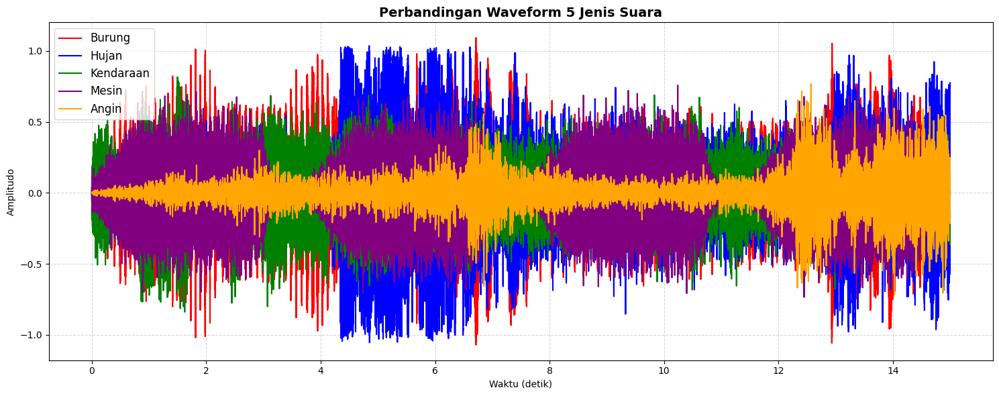

In [55]:
import librosa
import librosa.display
import matplotlib.pyplot as plt
import numpy as np

durasi = 15

def potong_sinyal(y, sr, durasi):
    max_len = int(sr * durasi)
    return y[:max_len]

y1 = potong_sinyal(y_burung, sr_burung, durasi)
y2 = potong_sinyal(y_hujan, sr_hujan, durasi)
y3 = potong_sinyal(y_kendaraan, sr_kendaraan, durasi)
y4 = potong_sinyal(y_mesin, sr_mesin, durasi)
y5 = potong_sinyal(y_angin, sr_angin, durasi)

t = np.linspace(0, durasi, len(y1))

plt.figure(figsize=(15, 6))

plt.plot(t, y1, label="Burung", color="red")
plt.plot(t, y2, label="Hujan", color="blue")
plt.plot(t, y3, label="Kendaraan", color="green")
plt.plot(t, y4, label="Mesin", color="purple")
plt.plot(t, y5, label="Angin", color="orange")

plt.title("Perbandingan Waveform 5 Jenis Suara", fontsize=14, fontweight='bold')
plt.xlabel("Waktu (detik)")
plt.ylabel("Amplitudo")
plt.grid(True, linestyle="--", alpha=0.5)
plt.legend(fontsize=12)
plt.tight_layout()

plt.show()

## **Menggabungkan 5 Jenis Suara Metode FFT**

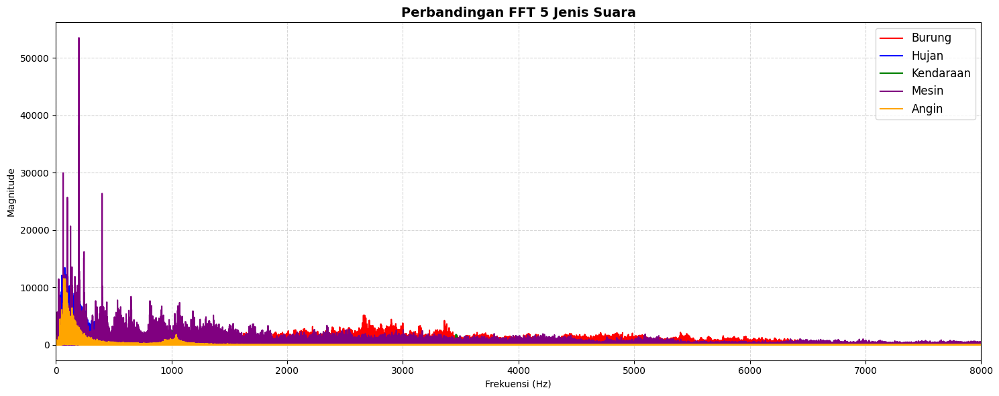

In [56]:
def hitung_fft(y, sr):
    n = len(y)
    fft = np.fft.fft(y)
    magnitude = np.abs(fft)[:n//2]
    frekuensi = np.linspace(0, sr/2, n//2)
    return frekuensi, magnitude

plt.figure(figsize=(15, 6))

sr = sr_burung

f1, m1 = hitung_fft(y_burung, sr)
plt.plot(f1, m1, label="Burung", color="red")

f2, m2 = hitung_fft(y_hujan, sr)
plt.plot(f2, m2, label="Hujan", color="blue")

f3, m3 = hitung_fft(y_kendaraan, sr)
plt.plot(f3, m3, label="Kendaraan", color="green")

f4, m4 = hitung_fft(y_mesin, sr)
plt.plot(f4, m4, label="Mesin", color="purple")

f5, m5 = hitung_fft(y_angin, sr)
plt.plot(f5, m5, label="Angin", color="orange")

plt.title("Perbandingan FFT 5 Jenis Suara", fontsize=14, fontweight='bold')
plt.xlabel("Frekuensi (Hz)")
plt.ylabel("Magnitude")
plt.xlim(0, 8000)
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(fontsize=12)
plt.tight_layout()
plt.show()